## Task One of the Detheon ML and DS Internship
### Abdul-Azeez Mahmud Gambo | mahmudabdulazeez9@gmail.com

#### Approach
1. Load the benchmark dataset using Pandas. 
2. Perform exploratory pairplots with Seaborn. 
3. Normalize features using StandardScaler(). 
4. Train LogisticRegression and DecisionTreeClassifier. 
5. Plot the confusion matrix heatmap and plot the decision boundary visualization.

In [4]:
!pip install seaborn

In [1]:
import pandas as pd # For data manipulation
import matplotlib.pyplot as plt # For visualisation
import seaborn as sns # For visualisation
import numpy as np # For mathematical operations and multi-dimensional array cal.
from sklearn.model_selection import train_test_split # Romdomly splits data into train and testing subsets
from sklearn.preprocessing import StandardScaler # Standardises features to have a mean of 0 and a standard deviation of 1
from sklearn.linear_model import LogisticRegression # A linear model used for classification tasks
from sklearn.tree import DecisionTreeClassifier # Non-linear model that makes predictions by splitting data into tree-like decision branchess
from sklearn.metrics import ConfusionMatrixDisplay # Visualises model confusion matrices to evaluate classification accuracy across classes


#### Loading benchmark dataset

In [2]:
# Loading benchmark dataset using Pandas
df = pd.read_csv("iris.csv")

In [3]:
#Previewing the first 5 rows of the data
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# Previewing the last 5 rows of the data
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


#### Exploratory Pairplots

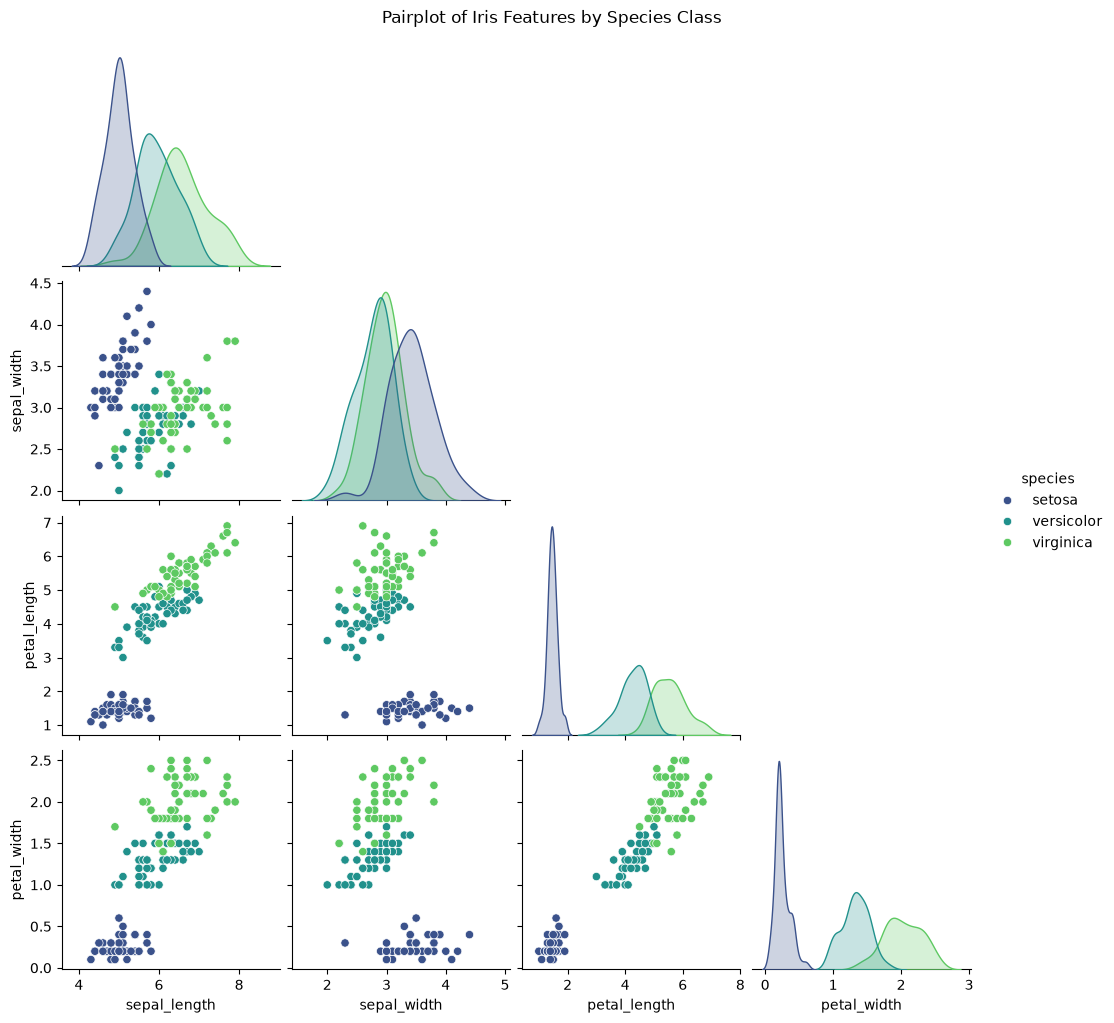

In [5]:
# Performing Exploratory Pairplots with Seaborn
sns.pairplot(df, hue="species", palette="viridis", corner=True)
plt.suptitle("Pairplot of Iris Features by Species Class", y=1.02) #The y=1.02 is to provide space after the title
plt.show()

#### Normalising Features using StandardScaler()

In [7]:
# Separating features (X) and target (y)
X = df.drop(columns="species")
y = df["species"]

#Train-Test splitting (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Standardising features (Mean = 0, Std Dev = 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Training LogisticRegression nad DecisionTreeClassifier

In [8]:
#Initialising models
log_reg = LogisticRegression(random_state=42)
dt_clf = DecisionTreeClassifier(random_state=42, max_depth=3)

#Training models
log_reg.fit(X_train_scaled, y_train)
dt_clf.fit(X_train_scaled, y_train)

#Previewing models accuracy
print(f"Logistic Regression Tree Accuracy: {log_reg.score(X_test_scaled, y_test):.2f}")
print(f"Decision Tree Classifier Accuracy: {dt_clf.score(X_test_scaled, y_test):2f}")

Logistic Regression Tree Accuracy: 0.93
Decision Tree Classifier Accuracy: 0.966667


#### Plotting Confusion Matrix and Decision Boundary

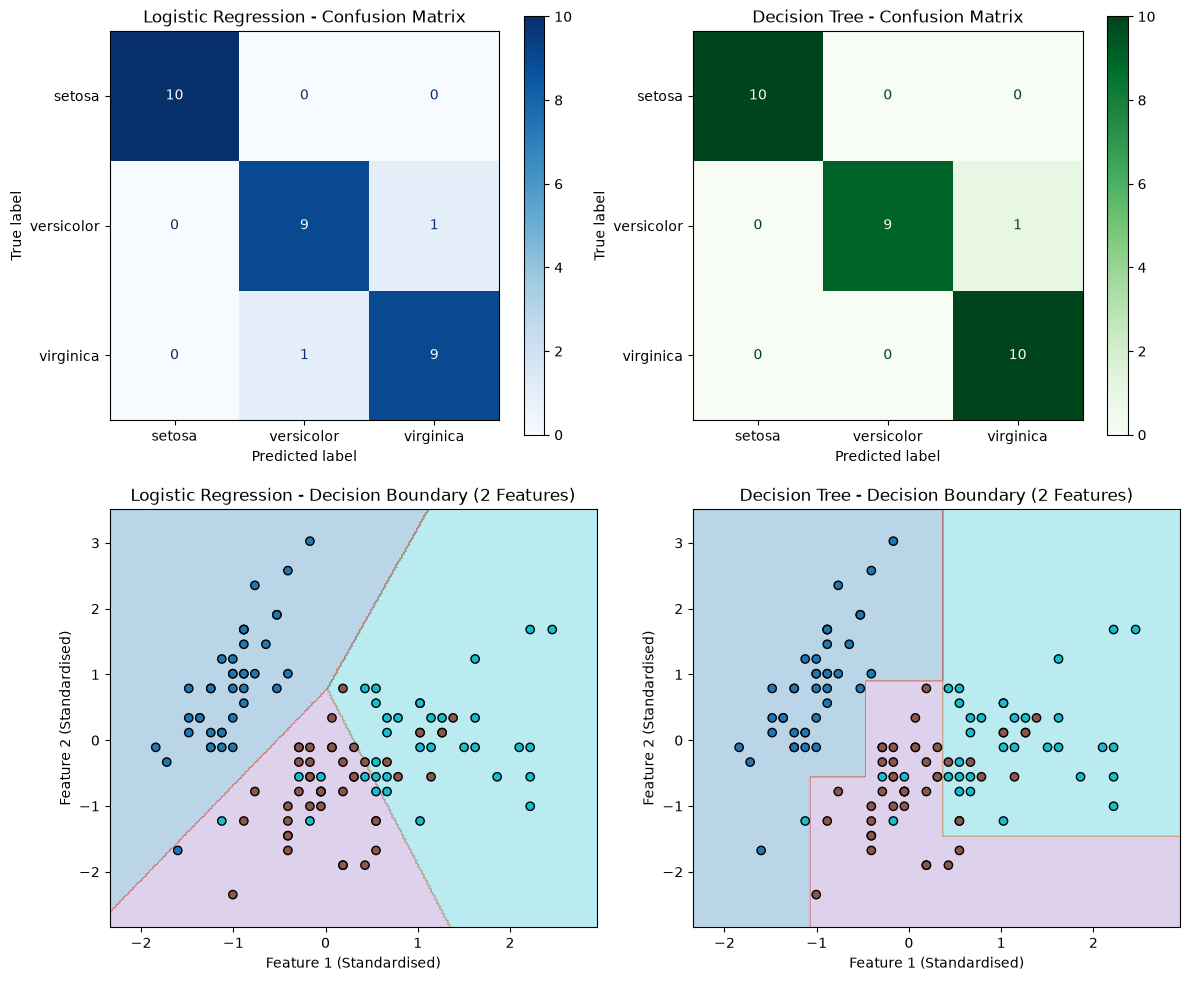

In [9]:
from sklearn.preprocessing import LabelEncoder

# Creating plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# --- 1. Confusion Matrix: Logistic Regression ---
ConfusionMatrixDisplay.from_estimator(
    log_reg, X_test_scaled, y_test, cmap="Blues", ax=axes[0, 0]
)
axes[0, 0].set_title("Logistic Regression - Confusion Matrix")

# --- 2. Confusion Matrix: Decision Tree ---
ConfusionMatrixDisplay.from_estimator(
    dt_clf, X_test_scaled, y_test, cmap="Greens", ax=axes[0, 1]
)
axes[0, 1].set_title("Decision Tree - Confusion Matrix")

# --- Encode y_train to numeric integers (handles string labels safely) ---
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# --- Helper Function for Decision Boundary (2d projection) ---
X_2d = X_train_scaled[:, :2]  # Using Sepal Length and Sepal Width
log_reg_2d = LogisticRegression(random_state=42).fit(X_2d, y_train_encoded)
dt_clf_2d = DecisionTreeClassifier(random_state=42, max_depth=3).fit(
    X_2d, y_train_encoded
)

x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02)
)

# --- 3. Decision Boundary: Logistic Regression ---
Z_lr = log_reg_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1, 0].contourf(xx, yy, Z_lr, alpha=0.3, cmap="tab10")
axes[1, 0].scatter(
    X_2d[:, 0], X_2d[:, 1], c=y_train_encoded, cmap="tab10", edgecolors="k"
)
axes[1, 0].set_title("Logistic Regression - Decision Boundary (2 Features)")
axes[1, 0].set_xlabel("Feature 1 (Standardised)")
axes[1, 0].set_ylabel("Feature 2 (Standardised)")

# --- 4. Decision Boundary: Decision Tree ---
Z_dt = dt_clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1, 1].contourf(xx, yy, Z_dt, alpha=0.3, cmap="tab10")
axes[1, 1].scatter(
    X_2d[:, 0], X_2d[:, 1], c=y_train_encoded, cmap="tab10", edgecolors="k"
)
axes[1, 1].set_title("Decision Tree - Decision Boundary (2 Features)")
axes[1, 1].set_xlabel("Feature 1 (Standardised)")
axes[1, 1].set_ylabel("Feature 2 (Standardised)")

plt.tight_layout()
plt.show()